# 02 - Random Forest vs XGBoost vs Ensembles: Will it rain tomorrow in Sri Lanka?

**MSc Applied Machine Learning class activity.** This notebook is the stand-alone submission: it needs only the dataset CSV and runs from top to bottom.

| | |
|---|---|
| **Local dataset** | Sri Lanka Weather Dataset (Kaggle, rasulmah, CC0). Daily weather of 30 Sri Lankan cities, 2010 to June 2023, source Open-Meteo |
| **Problem** | Binary **classification**: will a city get at least 1 mm of rain tomorrow? |
| **Models** | Random Forest, XGBoost, Soft Voting (RF + XGBoost), Stacking (RF + XGBoost with a Logistic Regression meta-learner) |
| **Test design** | Train on the earliest 80% of dates, test on the latest 20% (no shuffling) |

Contents: 1. Data and preprocessing, 2. Hyperparameter design and tuning, 3. Training, 4. Evaluation and comparison, 5. Pickle export and single-sample inference, 6. Strengths, limitations and interpretation.

*Run time: 5 to 10 minutes, mostly the hyperparameter search. Set `RUN_SEARCH = False` in section 2 to skip the search and use the stored result (1 to 2 minutes).*

In [1]:
import pickle, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import KFold, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
RAIN_THRESHOLD_MM = 1.0            # wet-day threshold used in climate studies
TEST_FRACTION = 0.20
CLASS_LABELS = {0: "No rain", 1: "Rain"}

# The CSV is looked for next to the notebook first, then in the project's data folder
RAW_FILE = next(p for p in [Path("SriLanka_Weather_Dataset.csv"),
                            Path("../data/raw/SriLanka_Weather_Dataset.csv")] if p.exists())

COLORS = {"Random Forest": "#2a78d6", "XGBoost": "#eb6834", "Soft Voting": "#1baf7a",
          "Stacking": "#eda100", "Baseline (same as today)": "#898781"}
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})
print("Data file:", RAW_FILE)

Data file: ..\data\raw\SriLanka_Weather_Dataset.csv


## 1. Data and preprocessing

### 1.1 Null detection and cleaning

In [2]:
df = pd.read_csv(RAW_FILE).rename(columns={"time": "date"})
df["date"] = pd.to_datetime(df["date"])
print("Shape:", df.shape, "| cities:", df["city"].nunique(),
      "|", df["date"].min().date(), "to", df["date"].max().date())

# --- null value detection ---
print("\nMissing values in the whole table:", int(df.isna().sum().sum()))
print("Duplicate (city, date) rows       :", int(df.duplicated(["city", "date"]).sum()))
print("Negative rain values              :", int((df["rain_sum"] < 0).sum()))

# --- cleaning: drop columns that carry no extra information ---
#  country (always 'Sri Lanka'), snowfall_sum (always 0), precipitation_sum (= rain_sum),
#  apparent_temperature_* (calculated from temperature), weathercode (summary of today's rain),
#  sunrise / sunset (day length hardly changes near the equator; the date features cover the season)
df["city"] = df["city"].str.strip()
df = df.drop(columns=["country", "snowfall_sum", "precipitation_sum", "apparent_temperature_max",
                      "apparent_temperature_min", "apparent_temperature_mean", "weathercode",
                      "sunrise", "sunset"])
print("\nColumns kept:", list(df.columns))

Shape: (147480, 24) | cities: 30 | 2010-01-01 to 2023-06-17

Missing values in the whole table: 0
Duplicate (city, date) rows       : 0
Negative rain values              : 0

Columns kept: ['date', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'shortwave_radiation_sum', 'rain_sum', 'precipitation_hours', 'windspeed_10m_max', 'windgusts_10m_max', 'winddirection_10m_dominant', 'et0_fao_evapotranspiration', 'latitude', 'longitude', 'elevation', 'city']


The raw data has **no missing values**, so nothing has to be filled in here. Imputation is still part of the model pipeline below (median for numbers, most frequent value for categories). It is fitted on the training data and protects the model if new data or the app sends a blank value.

### 1.2 Feature engineering and target (past values only)

In [3]:
def monsoon_season(month):
    """Sri Lanka's four climate seasons (Department of Meteorology)."""
    if month in (3, 4):   return "First inter-monsoon"
    if 5 <= month <= 9:   return "Southwest monsoon"
    if month in (10, 11): return "Second inter-monsoon"
    return "Northeast monsoon"

df = df.sort_values(["city", "date"])
rain = df.groupby("city")["rain_sum"]

# History features look BACKWARDS only (shift / rolling), so nothing from the future leaks in
df["rain_yesterday"]   = rain.shift(1)
df["rain_2_days_ago"]  = rain.shift(2)
df["rain_last_7_days"] = rain.transform(lambda s: s.rolling(7).sum())
df["rain_last_3_days_mean"] = (df["rain_sum"] + df["rain_yesterday"] + df["rain_2_days_ago"]) / 3

# Target looks one day FORWARD: did it rain tomorrow?
rain_next_day = rain.shift(-1)
df["rain_tomorrow"] = (rain_next_day >= RAIN_THRESHOLD_MM).astype(float)
df.loc[rain_next_day.isna(), "rain_tomorrow"] = np.nan

before = len(df)
df = df.dropna(subset=["rain_last_7_days", "rain_tomorrow"])    # first 6 days and last day of each city
df["rain_tomorrow"] = df["rain_tomorrow"].astype(int)
print("Rows removed (no 7-day history or no next day):", before - len(df))

# Calendar features
df["month"] = df["date"].dt.month
df["monsoon_season"] = df["month"].map(monsoon_season)
angle = 2 * np.pi * df["date"].dt.dayofyear / 365.25           # the year is a circle: 31 Dec is next to 1 Jan
df["day_of_year_sin"], df["day_of_year_cos"] = np.sin(angle), np.cos(angle)
wind = np.deg2rad(df["winddirection_10m_dominant"])            # wind direction is a circle too
df["wind_dir_sin"], df["wind_dir_cos"] = np.sin(wind), np.cos(wind)
df["temp_range"] = df["temperature_2m_max"] - df["temperature_2m_min"]   # small range = cloudy, humid day

SKEWED = ["rain_sum", "rain_yesterday", "rain_2_days_ago", "rain_last_7_days",
          "rain_last_3_days_mean", "elevation"]
NUMERIC = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "temp_range",
           "shortwave_radiation_sum", "precipitation_hours", "windspeed_10m_max", "windgusts_10m_max",
           "wind_dir_sin", "wind_dir_cos", "et0_fao_evapotranspiration", "latitude", "longitude",
           "month", "day_of_year_sin", "day_of_year_cos"]
CATEGORICAL = ["city", "monsoon_season"]
FEATURES = SKEWED + NUMERIC + CATEGORICAL
print("Number of model features:", len(FEATURES))

pd.DataFrame({"skew_before": df[SKEWED].skew(), "skew_after_log1p": np.log1p(df[SKEWED]).skew()}).round(2)

Rows removed (no 7-day history or no next day): 210


Number of model features: 24


,skew_before,skew_after_log1p
rain_sum,5.98,0.41
rain_yesterday,5.98,0.41
rain_2_days_ago,5.98,0.41
rain_last_7_days,2.63,-0.71
rain_last_3_days_mean,3.84,0.14
elevation,3.20,0.82


Rain amounts are heavily right-skewed (skewness about 6). `log1p` reduces this to about 0.4, so these columns get a log transform before scaling.

### 1.3 Single-sample hold-out and time-ordered split

In [4]:
# ONE record is taken out completely: the most recent complete day for Colombo.
# It is used only in section 5 for the inference demonstration.
last_day = df.loc[df["city"] == "Colombo", "date"].max()
is_holdout = (df["city"] == "Colombo") & (df["date"] == last_day)
holdout = df[is_holdout].copy()
df = df[~is_holdout]
print("Held-out sample:", holdout["city"].iloc[0], holdout["date"].iloc[0].date())

# Chronological split: the earliest 80% of dates train, the latest 20% test. No shuffling.
dates = np.sort(df["date"].unique())
cut_date = dates[int(len(dates) * (1 - TEST_FRACTION))]
df = df.sort_values(["date", "city"])
train, test = df[df["date"] < cut_date], df[df["date"] >= cut_date]
X_train, y_train = train[FEATURES], train["rain_tomorrow"]
X_test, y_test = test[FEATURES], test["rain_tomorrow"]

print(f"Train: {len(train):,} rows, {train['date'].min().date()} to {train['date'].max().date()}, Rain = {y_train.mean():.1%}")
print(f"Test : {len(test):,} rows, {test['date'].min().date()} to {test['date'].max().date()}, Rain = {y_test.mean():.1%}")

Held-out sample: Colombo 2023-06-16


Train: 117,810 rows, 2010-01-07 to 2020-10-07, Rain = 66.3%
Test : 29,459 rows, 2020-10-08 to 2023-06-16, Rain = 70.1%


**Class balance.** About 66% of training days are rainy. The imbalance is moderate, and it is handled inside the models: `class_weight="balanced"` for Random Forest and `scale_pos_weight` (dry days / rainy days) for XGBoost. Without this, a model can reach high accuracy by saying "Rain" too often and missing dry days.

### 1.4 Imputation, transformation, scaling and encoding in one pipeline

In [5]:
def make_preprocessor():
    """Fitted on training data only, because it sits inside each model pipeline.

    Tree models do not need scaling (they only ask "is the value above this split point?").
    Scaling is kept so every model gets the same input, and because the Logistic Regression
    meta-learner in stacking does need it.
    """
    skewed = Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("scale", StandardScaler())])
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("skewed", skewed, SKEWED), ("numeric", numeric, NUMERIC),
                              ("categorical", categorical, CATEGORICAL)])

def with_preprocessing(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

print("Columns after preprocessing:", make_preprocessor().fit_transform(X_train.head(5000)).shape[1])

Columns after preprocessing: 55


## 2. Hyperparameter design and tuning

No default values are used. The training set is large (about 118,000 rows) but the target is noisy: tomorrow's rain can never be known exactly from today's weather. So every value is chosen to **stop the trees from memorising noise**.

**Random Forest (bagging)**

| Parameter | Designed value | Why |
|---|---|---|
| `n_estimators` | 150 | Enough trees for a stable average; more only adds time |
| `max_depth` | 8 | The main signal (rain today, season) needs only a few splits |
| `min_samples_split` | 100 | A node needs 100 days before it may split |
| `min_samples_leaf` | 50 | Each leaf averages at least 50 days, giving smoother probabilities |
| `max_features` | "sqrt" | Random subset of features per split, so trees differ from each other |
| `bootstrap`, `max_samples` | True, 0.5 | Each tree sees a random half of the rows: more variety, faster training |
| `class_weight` | "balanced" | Stops the model ignoring the smaller class (dry days) |

**XGBoost (boosting)**

| Parameter | Designed value | Why |
|---|---|---|
| `n_estimators`, `learning_rate` | 300, 0.05 | Many small steps: each tree corrects only 5% of the remaining error |
| `max_depth` | 5 | Boosting works best with small trees |
| `subsample`, `colsample_bytree` | 0.8, 0.8 | Random rows and features per tree reduce overfitting |
| `min_child_weight` | 5 | One unusual day cannot create its own rule |
| `gamma` | 0.1 | A split must reduce the loss by at least 0.1 |
| `reg_alpha`, `reg_lambda` | 0.1, 1.5 | L1 and L2 penalties on leaf weights |
| `objective`, `eval_metric` | binary:logistic, logloss | Two classes, probability output |

In [6]:
RF_DESIGNED = dict(n_estimators=150, max_depth=8, min_samples_split=100, min_samples_leaf=50,
                   max_features="sqrt", bootstrap=True, max_samples=0.5, class_weight="balanced")
XGB_DESIGNED = dict(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
                    colsample_bytree=0.8, min_child_weight=5, gamma=0.1, reg_alpha=0.1, reg_lambda=1.5,
                    objective="binary:logistic", eval_metric="logloss")

# Hand-designed search space around the designed values
RF_SEARCH = {"model__n_estimators": [100, 150, 200], "model__max_depth": [6, 8, 10],
             "model__min_samples_split": [40, 100, 200], "model__min_samples_leaf": [20, 50, 100],
             "model__max_features": ["sqrt", 0.5], "model__max_samples": [0.3, 0.5, 0.7]}
XGB_SEARCH = {"model__n_estimators": [200, 300, 400], "model__learning_rate": [0.03, 0.05, 0.1],
              "model__max_depth": [3, 4, 5, 6], "model__subsample": [0.7, 0.8, 0.9],
              "model__colsample_bytree": [0.7, 0.8, 0.9], "model__min_child_weight": [1, 5, 10],
              "model__gamma": [0, 0.1, 0.5], "model__reg_alpha": [0, 0.1, 1.0],
              "model__reg_lambda": [1.0, 1.5, 3.0]}

# XGBoost weight for the positive class = dry days / rainy days (below 1: Rain is the larger class)
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

def make_rf(params):
    return RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1)

def make_xgb(params):
    return XGBClassifier(**params, scale_pos_weight=scale_pos_weight, tree_method="hist",
                         random_state=RANDOM_STATE, n_jobs=-1)

**Tuning method.** `RandomizedSearchCV` tries 10 random combinations per model. The folds come from `TimeSeriesSplit(n_splits=5)`: each fold trains on earlier days and validates on later days, the same way the model is used in real life. A shuffled K-fold would let the model see the future. The score is ROC-AUC because it does not depend on a single probability cut-off.

In [7]:
RUN_SEARCH = True      # False = skip the search and use the result stored below

# Result of the search (same seed), stored so the notebook can also run quickly
RF_STORED = {**RF_DESIGNED, "n_estimators": 100, "max_depth": 10, "min_samples_split": 200,
             "min_samples_leaf": 50, "max_features": 0.5, "max_samples": 0.3}
XGB_STORED = {**XGB_DESIGNED, "n_estimators": 200, "learning_rate": 0.03, "max_depth": 4,
              "subsample": 0.9, "colsample_bytree": 0.9, "min_child_weight": 5, "gamma": 0.5,
              "reg_alpha": 0, "reg_lambda": 1.0}

def tune(name, model, space):
    search = RandomizedSearchCV(with_preprocessing(model), space, n_iter=10, scoring="roc_auc",
                                cv=TimeSeriesSplit(n_splits=5), random_state=RANDOM_STATE, n_jobs=1)
    start = time.time()
    search.fit(X_train, y_train)
    print(f"{name}: best cross-validated ROC-AUC = {search.best_score_:.4f} ({time.time() - start:.0f} s)")
    return {k.replace("model__", ""): v for k, v in search.best_params_.items()}

if RUN_SEARCH:
    rf_tuned = {**RF_DESIGNED, **tune("Random Forest", make_rf(RF_DESIGNED), RF_SEARCH)}
    xgb_tuned = {**XGB_DESIGNED, **tune("XGBoost", make_xgb(XGB_DESIGNED), XGB_SEARCH)}
else:
    rf_tuned, xgb_tuned = RF_STORED, XGB_STORED

rows = [("Random Forest", k, RF_DESIGNED[k], rf_tuned[k]) for k in RF_DESIGNED]
rows += [("XGBoost", k, XGB_DESIGNED[k], xgb_tuned[k]) for k in XGB_DESIGNED]
params_table = pd.DataFrame(rows, columns=["model", "parameter", "designed", "tuned"])
params_table["changed"] = params_table["designed"].astype(str) != params_table["tuned"].astype(str)
params_table

Random Forest: best cross-validated ROC-AUC = 0.8941 (166 s)


XGBoost: best cross-validated ROC-AUC = 0.8945 (104 s)


,model,parameter,designed,tuned,changed
0,Random Forest,n_estimators,150,100,True
1,Random Forest,max_depth,8,10,True
2,Random Forest,min_samples_split,100,200,True
3,Random Forest,min_samples_leaf,50,50,False
4,Random Forest,max_features,sqrt,0.5,True
5,Random Forest,bootstrap,True,True,False
6,Random Forest,max_samples,0.5,0.3,True
7,Random Forest,class_weight,balanced,balanced,False
8,XGBoost,n_estimators,300,200,True
9,XGBoost,learning_rate,0.05,0.03,True


**What the search changed, and why it makes sense**

- **Random Forest:** slightly deeper trees (`max_depth` 8 to 10) but with stronger limits everywhere else: a node needs 200 days to split, each tree sees only 30% of the rows, and each split may look at half of the features. Because the two strongest features (rain today, rain hours today) dominate, letting more features compete at each split helps, while smaller row samples keep the trees different from each other. 100 trees were enough.
- **XGBoost:** the search moved towards a **simpler** model: fewer trees (300 to 200), smaller steps (learning rate 0.05 to 0.03), shallower trees (5 to 4) and a stronger split penalty (`gamma` 0.1 to 0.5). For a noisy target, simpler trees generalise better to later years.
- The cross-validated ROC-AUC of the two models is almost the same (about 0.894), and several XGBoost combinations score almost equally. So the winning XGBoost combination can change between machines, and no parameter has a big effect. The data limits the accuracy more than the settings do.

## 3. Training the four models

- **Soft voting** combines the models with a **fixed rule**: the predicted probabilities of Random Forest and XGBoost are averaged, and the class with the higher average wins.
- **Stacking learns the combination**: a Logistic Regression meta-learner is trained on the base models' out-of-fold probabilities and decides how much to trust each one.

Note on stacking folds: `StackingClassifier` needs folds where every row is predicted exactly once. `TimeSeriesSplit` does not do that (its first block is never predicted), so `KFold` **without shuffling** is used: five blocks of consecutive days, and neighbouring days are never mixed between folds.

In [8]:
models = {
    "Random Forest": with_preprocessing(make_rf(rf_tuned)),
    "XGBoost": with_preprocessing(make_xgb(xgb_tuned)),
    "Soft Voting": with_preprocessing(VotingClassifier(
        estimators=[("rf", make_rf(rf_tuned)), ("xgb", make_xgb(xgb_tuned))], voting="soft")),
    "Stacking": with_preprocessing(StackingClassifier(
        estimators=[("rf", make_rf(rf_tuned)), ("xgb", make_xgb(xgb_tuned))],
        final_estimator=LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
        stack_method="predict_proba", cv=KFold(n_splits=5, shuffle=False))),
}
train_time = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time[name] = time.time() - start
    print(f"{name:14s} trained in {train_time[name]:5.1f} s")

Random Forest  trained in   5.1 s


XGBoost        trained in   2.7 s


Soft Voting    trained in   6.7 s


Stacking       trained in  32.7 s


## 4. Evaluation and comparison

All models are scored on the **same** test set (8 October 2020 to 16 June 2023), which none of them saw during training or tuning.

A **baseline** is added for honesty: "tomorrow will be the same as today" (rain tomorrow if it rained today). It uses no machine learning. A model is only useful if it beats this rule.

In [9]:
BASELINE = "Baseline (same as today)"

def all_metrics(y_true, y_pred, y_prob=None):
    out = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):       # macro: both classes count equally; weighted: by class size
        out[f"precision_{avg}"] = precision_score(y_true, y_pred, average=avg)
        out[f"recall_{avg}"] = recall_score(y_true, y_pred, average=avg)
        out[f"f1_{avg}"] = f1_score(y_true, y_pred, average=avg)
    out["roc_auc"] = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    return out

preds = {BASELINE: (test["rain_sum"] >= RAIN_THRESHOLD_MM).astype(int).to_numpy()}
probs, rows = {}, []
rows.append({"model": BASELINE, **all_metrics(y_test, preds[BASELINE]),
             "train_accuracy": accuracy_score(y_train, (train["rain_sum"] >= RAIN_THRESHOLD_MM).astype(int)),
             "training_time_s": 0.0})
for name, model in models.items():
    probs[name] = model.predict_proba(X_test)[:, 1]
    preds[name] = (probs[name] >= 0.5).astype(int)
    rows.append({"model": name, **all_metrics(y_test, preds[name], probs[name]),
                 "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
                 "training_time_s": train_time[name]})

results = pd.DataFrame(rows).set_index("model")
results["train_minus_test"] = results["train_accuracy"] - results["accuracy"]   # overfitting check
results.round(4).T

model,Baseline (same as today),Random Forest,XGBoost,Soft Voting,Stacking
accuracy,0.8033,0.7966,0.7996,0.7985,0.8154
precision_macro,0.7652,0.7610,0.7634,0.7626,0.7804
recall_macro,0.7653,0.7884,0.7879,0.7887,0.7747
f1_macro,0.7653,0.7704,0.7723,0.7718,0.7774
precision_weighted,0.8034,0.8135,0.8137,0.8140,0.8137
recall_weighted,0.8033,0.7966,0.7996,0.7985,0.8154
f1_weighted,0.8033,0.8016,0.8041,0.8033,0.8145
roc_auc,NaN,0.8732,0.8753,0.8750,0.8750
train_accuracy,0.8179,0.8325,0.8268,0.8298,0.8392
training_time_s,0.0000,5.1046,2.6611,6.7079,32.6705


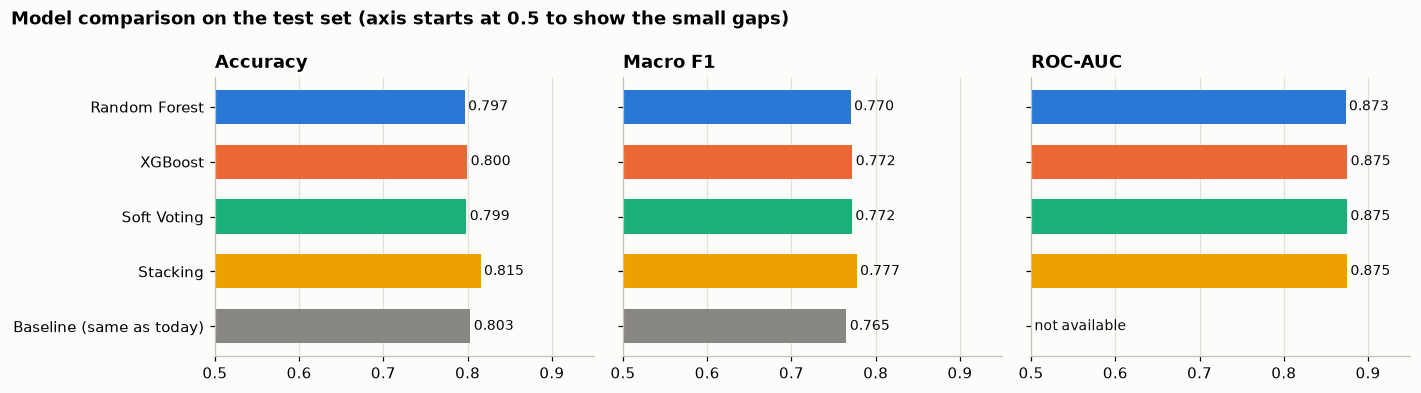

In [10]:
order = list(models) + [BASELINE]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (col, title) in zip(axes, [("accuracy", "Accuracy"), ("f1_macro", "Macro F1"), ("roc_auc", "ROC-AUC")]):
    values = results.loc[order, col]
    ax.barh(order, values.fillna(0), color=[COLORS[m] for m in order], height=0.62)
    for y_pos, v in enumerate(values):
        ax.text((v if pd.notna(v) else 0.5) + 0.004, y_pos, f"{v:.3f}" if pd.notna(v) else "not available",
                va="center", fontsize=9, color=INK)
    ax.set_xlim(0.5, 0.95); ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9]); ax.set_title(title)
    ax.grid(axis="y", visible=False); ax.invert_yaxis()
fig.suptitle("Model comparison on the test set (axis starts at 0.5 to show the small gaps)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

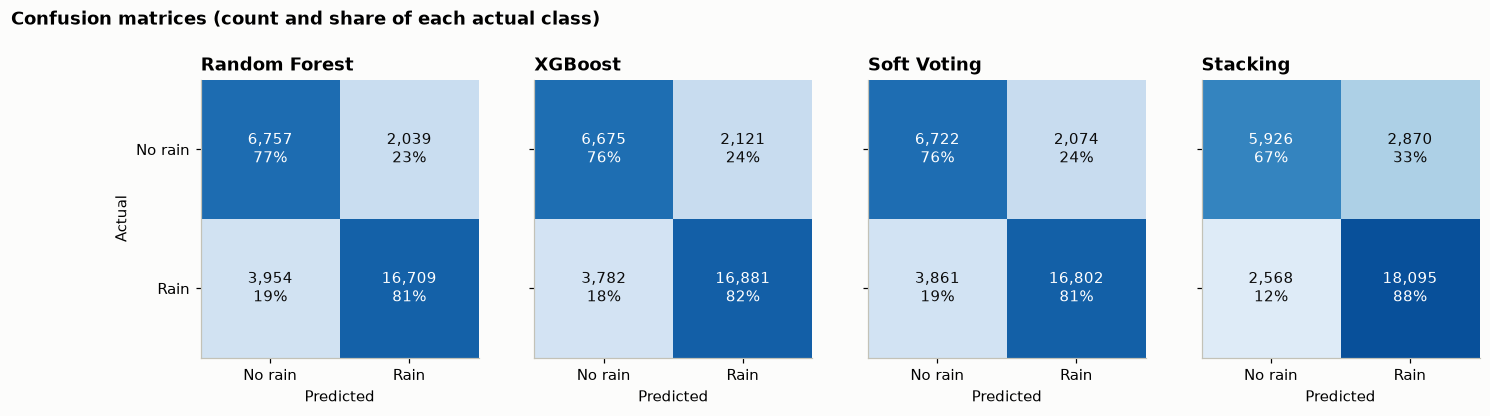

In [11]:
labels = ["No rain", "Rain"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center",
                    color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks([0, 1], labels); ax.set_xlabel("Predicted"); ax.set_title(name); ax.grid(False)
axes[0].set_yticks([0, 1], labels); axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrices (count and share of each actual class)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.show()

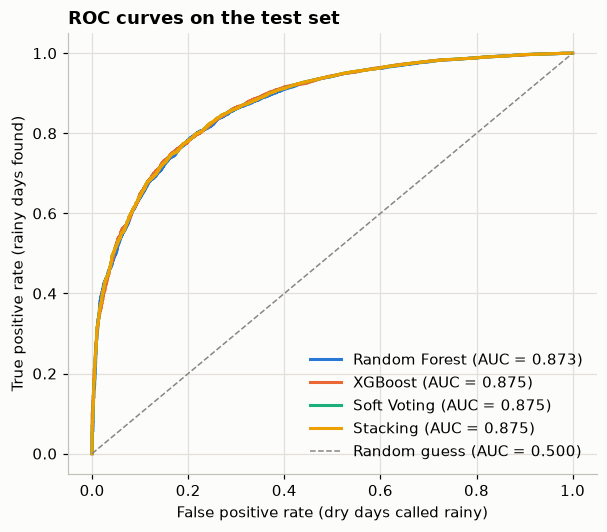

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC = {results.loc[name, 'roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate (dry days called rainy)"); ax.set_ylabel("True positive rate (rainy days found)")
ax.set_title("ROC curves on the test set"); ax.legend(loc="lower right")
plt.show()

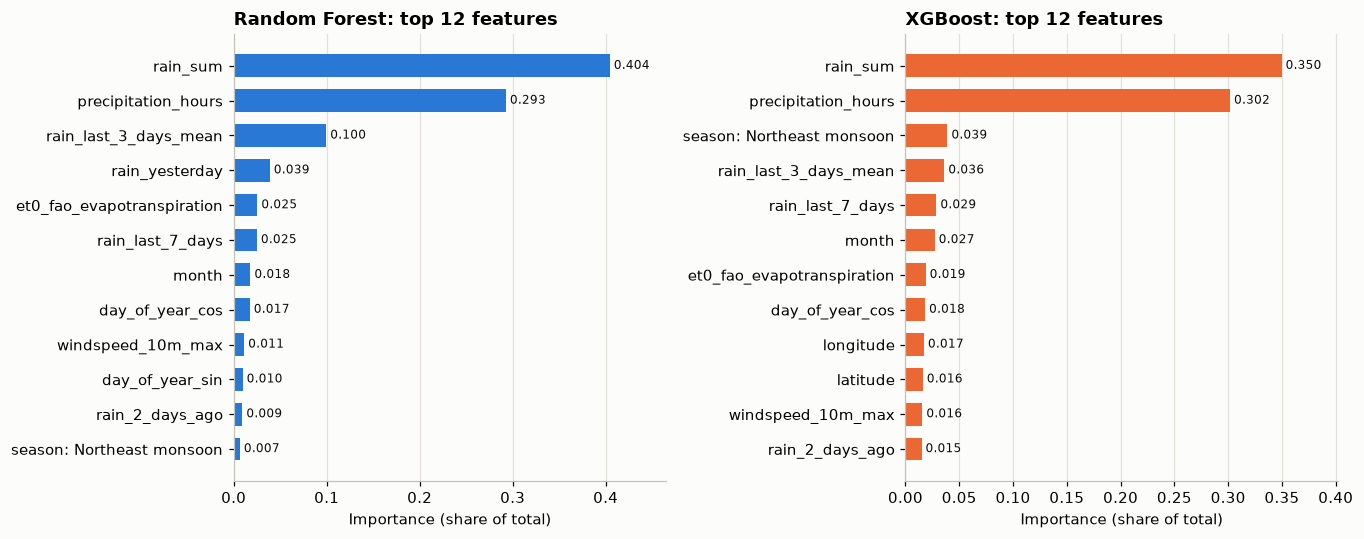

In [13]:
def clean(name):
    return (name.replace("skewed__", "").replace("numeric__", "").replace("categorical__", "")
                .replace("city_", "city: ").replace("monsoon_season_", "season: "))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    pipe = models[name]
    names = [clean(n) for n in pipe.named_steps["prep"].get_feature_names_out()]
    top = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values().tail(12)
    ax.barh(top.index, top.values, color=COLORS[name], height=0.65)
    for y_pos, v in enumerate(top.values):
        ax.text(v, y_pos, f" {v:.3f}", va="center", fontsize=8, color=INK)
    ax.set_title(f"{name}: top 12 features"); ax.set_xlabel("Importance (share of total)")
    ax.grid(axis="y", visible=False); ax.set_xlim(0, top.max() * 1.15)
plt.tight_layout(); plt.show()

In [14]:
# Where do the errors happen? Accuracy by monsoon season
correct = test[["monsoon_season"]].copy()
for name in order:
    correct[name] = (preds[name] == y_test.to_numpy()).astype(int)
by_season = correct.groupby("monsoon_season")[order].mean()
by_season["share_of_rainy_days"] = test.groupby("monsoon_season")["rain_tomorrow"].mean()
by_season["test_rows"] = test.groupby("monsoon_season").size()
by_season.round(3)

,Random Forest,XGBoost,Soft Voting,Stacking,Baseline (same as today),share_of_rainy_days,test_rows
monsoon_season,,,,,,,
First inter-monsoon,0.753,0.757,0.756,0.790,0.768,0.709,5490
Northeast monsoon,0.696,0.702,0.700,0.723,0.721,0.478,8100
Second inter-monsoon,0.858,0.852,0.859,0.852,0.854,0.816,5280
Southwest monsoon,0.866,0.870,0.866,0.881,0.859,0.811,10589


## 5. Pickle export and single-sample inference

The soft-voting pipeline (preprocessing + ensemble) is saved with `pickle`, loaded back from the file, and used to predict the **one record that was kept out** of both training and testing.

In [15]:
ensemble_model = models["Soft Voting"]
pickle.dump(ensemble_model, open("model_from_notebook.pkl", "wb"))        # export
loaded_model = pickle.load(open("model_from_notebook.pkl", "rb"))          # load back

sample = holdout[FEATURES]
predicted = int(loaded_model.predict(sample)[0])
probability = loaded_model.predict_proba(sample)[0]
truth = int(holdout["rain_tomorrow"].iloc[0])

shown = ["date", "city", "temperature_2m_max", "temperature_2m_min", "rain_sum", "precipitation_hours",
         "rain_yesterday", "rain_2_days_ago", "rain_last_7_days", "monsoon_season"]
print(holdout[shown].T.to_string(header=False))
print(f"\nPredicted class: {predicted} ({CLASS_LABELS[predicted]})")
print(f"Probabilities  : No rain = {probability[0]:.3f}, Rain = {probability[1]:.3f}")
print(f"True label     : {truth} ({CLASS_LABELS[truth]})  ->  {'CORRECT' if predicted == truth else 'INCORRECT'}")

date                 2023-06-16 00:00:00
city                             Colombo
temperature_2m_max                  30.2
temperature_2m_min                  26.5
rain_sum                             6.0
precipitation_hours                 24.0
rain_yesterday                       3.9
rain_2_days_ago                      8.9
rain_last_7_days                    73.6
monsoon_season         Southwest monsoon

Predicted class: 1 (Rain)
Probabilities  : No rain = 0.021, Rain = 0.979
True label     : 1 (Rain)  ->  CORRECT


## 6. Strengths, limitations and interpretation

The numbers quoted here are from the Windows run of this project. On another operating system XGBoost can differ in the third decimal place.

### 6.1 What the numbers say

- All four models reach **ROC-AUC of about 0.875**. They rank rainy and dry days well.
- **Accuracy is 0.80 to 0.82, which is about the same as the simple baseline (0.80).** At a plain yes/no answer the models hardly beat "tomorrow = today", because rain persistence is so strong (86% of rainy days are followed by another rainy day).
- The models are better where it matters more: **macro F1 is 0.770 to 0.777 against 0.765** for the baseline, and unlike the baseline they give a **probability**, which allows ranking days and cities by risk and choosing a different cut-off (for example, warn farmers only above 80%).
- The gap between train and test accuracy is small (2.4 to 3.6 percentage points), so the regularised settings prevented serious overfitting.

### 6.2 Random Forest vs XGBoost

| | Random Forest (bagging) | XGBoost (boosting) |
|---|---|---|
| **How it works** | Many independent deep-ish trees on random samples; their votes are averaged, which reduces variance | Small trees built one after another; each corrects the errors of the ones before, which reduces bias |
| **Observed result** | Accuracy 0.7965, macro F1 0.7702, ROC-AUC 0.8732 | Accuracy 0.7996, macro F1 0.7723, ROC-AUC 0.8753 (slightly better on these three) |
| **Training time** | About 5 s | About 3 s (about 2 times faster) |
| **Model file size** | About 3.8 MB | About 0.35 MB |
| **Strengths** | Hard to overfit, few sensitive parameters, trees train in parallel, good results even before tuning | Best single model here, fast, small, built-in regularisation (`gamma`, L1, L2), handles class imbalance with one parameter |
| **Limitations** | Slower and larger; puts 70% of its importance on two features (rain today, rain hours today), so it behaves close to the baseline | Many parameters that interact; easy to overfit with a high learning rate or deep trees (in the app's dashboard, XGBoost with learning rate 0.1 and depth 6 on 16,000 rows reached about 0.94 train accuracy but only about 0.80 test accuracy) |

### 6.3 The ensembles

- **Soft Voting** lands between its two members (accuracy 0.7985, ROC-AUC 0.8750). Averaging helps when the members make *different* mistakes. Here Random Forest and XGBoost use the same features and make very similar errors, so there is little to gain. Its strength is stability: it is never much worse than its better member.
- **Stacking** has the best accuracy (0.8154) and macro F1 (0.7774), with the same ROC-AUC (0.8750). The reason is worth understanding: the same ranking with higher accuracy means the meta-learner mainly **moved the decision threshold**. The base models use class weights, which push them to predict "No rain" more often; the Logistic Regression meta-learner is not weighted, so it shifts back towards "Rain" (about 88% of rainy days found, but only about 67% of dry days, against 76 to 77% for the others). Stacking costs about 4 times more training time than soft voting because the base models are trained six times.

### 6.4 Interpretation in the Sri Lankan context

- **What drives the prediction:** rain today, the number of rain hours today and the 3-day rain average carry about 69% (XGBoost) to 80% (Random Forest) of the importance. Season features come next: for XGBoost, "Northeast monsoon" is the third most important feature.
- **Errors follow the monsoons.** Accuracy is highest in the Southwest monsoon (about 0.87) and the Second inter-monsoon (about 0.86), when about 81% of days are rainy and the weather is stable. It is lowest in the **Northeast monsoon, December to February (about 0.70)**: only 48% of days are rainy, the weather switches between wet and dry spells, and the wet area moves to the north and east. This is the season where a forecast is most needed and hardest.
- **Location matters.** Accuracy is lowest for the dry-zone and hill-country cities (Badulla, Hambantota, Matale: 0.71 to 0.73) and highest in the wet zone (Ratnapura and the Colombo area: 0.83), where rain is more regular.

### 6.5 Limitations of this work

1. The data is from a weather model (Open-Meteo reanalysis), not from Department of Meteorology rain gauges. Rain is stored on a coarse grid: only 15 distinct rain series for 30 cities.
2. Important drivers of rain are missing: air pressure, humidity, cloud cover, and wider systems such as depressions in the Bay of Bengal.
3. The inputs are end-of-day values, so the prediction is for the next day only.
4. The "rainy day" threshold of 1 mm treats a light shower and a flood the same way.

### 6.6 Recommendation

**XGBoost** is the best single model: slightly better than Random Forest on accuracy, macro F1 and ROC-AUC, about 2 times faster and about 10 times smaller. The **soft-voting ensemble** is exported as `model.pkl` for the app because the activity asks for it, and it performs almost the same. Stacking gives the highest accuracy, but mainly through a different threshold, at about 4 times the training cost of soft voting. For real use, the predicted **probability** is more valuable than the yes/no answer.